In [1]:
import sys
sys.path.insert(0, "/home/botofan/ronlp-project")

from src.data_utils import get_laroseda, get_ronec
from collections import Counter
import matplotlib.pyplot as plt

laroseda = get_laroseda()
ronec    = get_ronec()

print("=== LaRoSeDa ===")
print(laroseda)
print("\n=== RONEC ===")
print(ronec)

=== LaRoSeDa ===
DatasetDict({
    train: Dataset({
        features: ['index', 'title', 'content', 'starRating'],
        num_rows: 12000
    })
    test: Dataset({
        features: ['index', 'title', 'content', 'starRating'],
        num_rows: 3000
    })
})

=== RONEC ===
DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_ids', 'space_after', 'ner_tags'],
        num_rows: 9000
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_ids', 'space_after', 'ner_tags'],
        num_rows: 1330
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_ids', 'space_after', 'ner_tags'],
        num_rows: 2000
    })
})


In [2]:
def to_binary(rating):
    if rating <= 2: return 0   # negative (1⭐, 2⭐)
    if rating >= 4: return 1   # positive (4⭐, 5⭐)
    return -1                  # neutral (not present in LaRoSeDa)

print("LaRoSeDa binary label distribution:")
for split in laroseda:
    labels = [to_binary(r) for r in laroseda[split]["starRating"]]
    counts = Counter(labels)
    print(f"  {split}: total={len(labels)}, neg(0)={counts[0]}, pos(1)={counts[1]}, neutral={counts[-1]}")

LaRoSeDa binary label distribution:
  train: total=12000, neg(0)=6000, pos(1)=6000, neutral=0
  test: total=3000, neg(0)=1500, pos(1)=1500, neutral=0


In [3]:
for binary_label, name in [(0, "NEGATIVE (1-2 stars)"), (1, "POSITIVE (4-5 stars)")]:
    print(f"\n=== {name} ===")
    count = 0
    for i in range(len(laroseda["train"])):
        s = laroseda["train"][i]
        if to_binary(s["starRating"]) == binary_label:
            print(f"  [{s['starRating']}⭐] {s['title'][:80]}")
            print(f"    {s['content'][:200]}\n")
            count += 1
            if count >= 3: break


=== NEGATIVE (1-2 stars) ===
  [1⭐] Foarte slab
    ca aspect este foarte frumoasa dar cine vrea sa se joace cu tastatura nu poate

  [1⭐] Țeapa de zile mari!!!
    in primul rand nu este de stica dupa cum spune producatorul, este una de plastic de nici 10 lei   calitatea este 0 a mea a venit gata zgariata plus de asta nu se lipeste pe ecran sub nici o forma desi

  [1⭐] Nu merita cumparate
    nu merita cumparate... sunt create cu limitare de volum. volumul lor este la jumate in comparatie cu al altor casti no name... chiar mai ieftine... ar trebui sa le returnez...


=== POSITIVE (4-5 stars) ===
  [5⭐] Foarte multumit
    se incarca repede si tine 3 incarcari complete ale telefonului.

  [5⭐] Recomand
    un ceas excelent. face cam tot ce ai nevoie cata vreme nu-l compari cu un telefon.  baterie tine mult, il am de 17zile si mai are 20% baterie folosit intens.  primesti notificarile in timp real, nu se

  [4⭐] Bun, dar pica de pe geam
    + e "teapan", lasa impresia de calitate.  + 

In [4]:
names = ronec["train"].features["ner_tags"].feature.names
print("Entity labels:", names)

counter = Counter()
for split in ronec:
    for tags in ronec[split]["ner_tags"]:
        for t in tags:
            counter[names[t]] += 1

print("\nTag frequencies across all splits:")
for tag, n in counter.most_common():
    print(f"  {tag:15s} {n:>8}")

Entity labels: ['O', 'B-PERSON', 'I-PERSON', 'B-ORG', 'I-ORG', 'B-GPE', 'I-GPE', 'B-LOC', 'I-LOC', 'B-NAT_REL_POL', 'I-NAT_REL_POL', 'B-EVENT', 'I-EVENT', 'B-LANGUAGE', 'I-LANGUAGE', 'B-WORK_OF_ART', 'I-WORK_OF_ART', 'B-DATETIME', 'I-DATETIME', 'B-PERIOD', 'I-PERIOD', 'B-MONEY', 'I-MONEY', 'B-QUANTITY', 'I-QUANTITY', 'B-NUMERIC', 'I-NUMERIC', 'B-ORDINAL', 'I-ORDINAL', 'B-FACILITY', 'I-FACILITY']

Tag frequencies across all splits:
  O                 412266
  B-PERSON           26130
  I-PERSON           13153
  I-ORG              12490
  I-DATETIME         11828
  B-GPE              11103
  B-DATETIME          9614
  B-ORG               7880
  B-NUMERIC           7735
  I-WORK_OF_ART       5523
  B-NAT_REL_POL       4970
  I-LOC               3066
  I-MONEY             2674
  I-EVENT             2523
  I-PERIOD            2490
  B-LOC               2467
  I-FACILITY          2275
  B-ORDINAL           1893
  I-GPE               1705
  B-WORK_OF_ART       1596
  B-QUANTITY          158

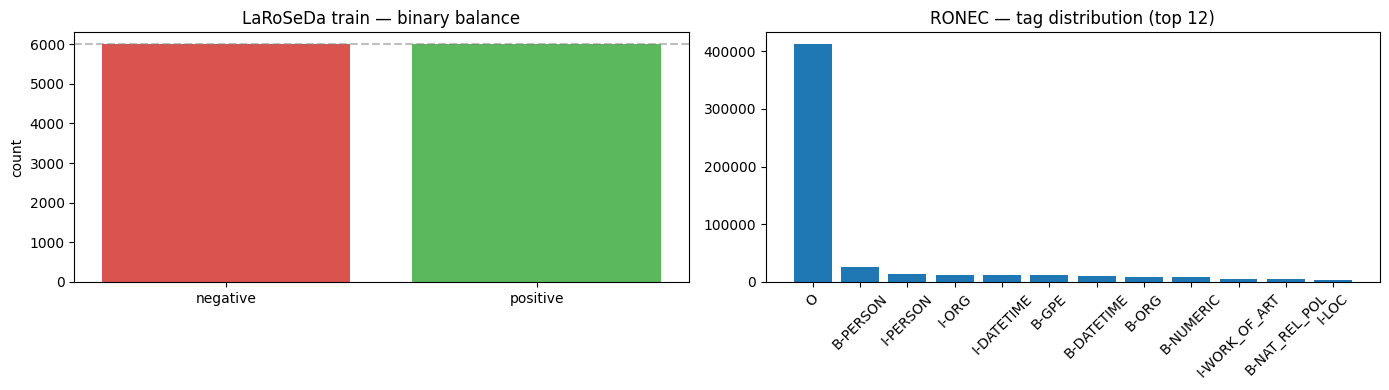

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

train_labels = [to_binary(r) for r in laroseda["train"]["starRating"]]
counts = Counter(train_labels)
axes[0].bar(["negative", "positive"], [counts[0], counts[1]], color=["#d9534f", "#5cb85c"])
axes[0].set_title("LaRoSeDa train — binary balance")
axes[0].set_ylabel("count")
axes[0].axhline(6000, color="gray", linestyle="--", alpha=0.5)   # balance line

top = counter.most_common(12)
axes[1].bar([t for t, _ in top], [c for _, c in top])
axes[1].set_title("RONEC — tag distribution (top 12)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [13]:
import sys
sys.path.insert(0, "/home/botofan/ronlp-project")

import os
import pickle
import numpy as np
import pandas as pd

from src.data_utils import get_laroseda, get_ronec
from src.preprocess import to_binary, combine_text

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.pipeline import Pipeline



In [15]:
laroseda = get_laroseda()

def build_laroseda_xy(split):
    ds = laroseda[split]
    X = [combine_text(t, c) for t, c in zip(ds["title"], ds["content"])]
    y = [to_binary(r) for r in ds["starRating"]]
    return X, np.array(y)

X_train, y_train = build_laroseda_xy("train")
X_test,  y_test  = build_laroseda_xy("test")

print(f"loaded: train={len(X_train)}, test={len(X_test)}")

loaded: train=12000, test=3000


In [17]:
MODEL_PATH = "/home/botofan/ronlp-project/models/tfidf_logreg_laroseda.pkl"

if os.path.exists(MODEL_PATH):
    pipe_lr = pickle.load(open(MODEL_PATH, "rb"))
    print("loaded from disk")
else:
    pipe_lr = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=50_000, ngram_range=(1,2),
                                   min_df=2, sublinear_tf=True, strip_accents="unicode")),
        ("clf", LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced")),
    ])
    pipe_lr.fit(X_train, y_train)
    os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
    pickle.dump(pipe_lr, open(MODEL_PATH, "wb"))
    print("trained and saved")

pred = pipe_lr.predict(X_test)
print(f"accuracy: {accuracy_score(y_test, pred):.4f}")
print(f"macro-F1: {f1_score(y_test, pred, average='macro'):.4f}")

trained and saved
accuracy: 0.9613
macro-F1: 0.9613


In [18]:
from src.preprocess import combine_text

def predict_sentiment(title, content):
    """Predict positive/negative for a Romanian review."""
    text = combine_text(title, content)
    pred = pipe_lr.predict([text])[0]
    proba = pipe_lr.predict_proba([text])[0]
    label = "POSITIVE ✅" if pred == 1 else "NEGATIVE ❌"
    print(f"Input:    {title} | {content[:100]}")
    print(f"Prediction: {label}")
    print(f"Confidence: neg={proba[0]:.3f}, pos={proba[1]:.3f}")
    print()
    return pred


# Try a few custom reviews:
predict_sentiment(
    "Foarte mulțumit",
    "Produsul a sosit repede și funcționează perfect. Recomand!"
)

predict_sentiment(
    "Dezastru",
    "Nu funcționează deloc, banii aruncați. Nu recomand nimănui."
)

predict_sentiment(
    "Okay",
    "Nu e nici bun nici rău, își face treaba."
)

predict_sentiment(
    "Baterie bună",
    "Ține toată ziua, dar camera e slabă."
)
predict_sentiment(
    "Perfect!",
    "Nu am avut nici o problema la utilizarea produsului!"
)

Input:    Foarte mulțumit | Produsul a sosit repede și funcționează perfect. Recomand!
Prediction: POSITIVE ✅
Confidence: neg=0.015, pos=0.985

Input:    Dezastru | Nu funcționează deloc, banii aruncați. Nu recomand nimănui.
Prediction: NEGATIVE ❌
Confidence: neg=0.965, pos=0.035

Input:    Okay | Nu e nici bun nici rău, își face treaba.
Prediction: POSITIVE ✅
Confidence: neg=0.335, pos=0.665

Input:    Baterie bună | Ține toată ziua, dar camera e slabă.
Prediction: POSITIVE ✅
Confidence: neg=0.448, pos=0.552

Input:    Perfect! | Nu am avut nici o problema la utilizarea produsului!
Prediction: POSITIVE ✅
Confidence: neg=0.351, pos=0.649



np.int64(1)

In [ ]:
## Dataset Summary

### LaRoSeDa — Romanian Product Review Sentiment
- **Source:** `universityofbucharest/laroseda` (HuggingFace)
- **Domain:** Romanian product reviews
- **Original label:** `starRating` (1–5 stars)
- **Binary mapping:** 1–2 ⭐ → negative (0), 4–5 ⭐ → positive (1)
- **No 3-star reviews** in the data (clean binary split)
- **Splits:** train 12,000 (6,000 / 6,000), test 3,000 (~1,500 / ~1,500)
- **Balance:** perfectly balanced → macro-F1 ≈ accuracy

### RONEC — Romanian Named Entity Corpus
- **Source:** `community-datasets/ronec` (HuggingFace)
- **Domain:** Romanian news
- **Schema:** token classification (BIO tagging)
- **Fields:** `tokens` (strings), `ner_tags` (BIO), `ner_ids` (integers), `space_after`
- **Splits:** train 9,000 / validation 1,330 / test 2,000
- **Entity types:** (fill from Cell 4)

### Preprocessing decisions
- Text input = `title + " " + content` (concatenate)
- Max sequence length = 256 tokens
- 3-star reviews: not present → no dropping needed
- RONEC: no preprocessing needed (standard BIO)